In [1]:
import os
import numpy as np
import h5py
from astropy.cosmology import Planck15
from scipy.interpolate import interp1d
from scipy.integrate import quad
from scipy.special import erf
import matplotlib.pyplot as plt
import matplotlib as mpl
import corner
from kaydee import KDE
import popodds

In [2]:
# set some constants for the plots
fs = 12
lw = 1.4
mpl.rcParams['font.size']=fs
mpl.rcParams['font.family']='serif'
mpl.rcParams['font.serif']='cmr10'
mpl.rcParams['mathtext.fontset']='cm'
mpl.rcParams['axes.unicode_minus']=False
mpl.rcParams['axes.formatter.use_mathtext']=True
mpl.rcParams['lines.linewidth']=lw

# GW241011 parameter estimation samples

In [3]:
# file = '/home/tristan-bruel/Documents/Science/LVK/o4a-astro/GW241011_GW241110_data_release/data/standard_pe/GW241011_posterior_samples_combined.h5'
# with h5py.File(file, 'r') as h:
    
#     pos = h['C00:IMRPhenomXO4a']['posterior_samples']
#     #pos = h['C00:IMRPhenomXPHM-SpinTaylor']['posterior_samples']
#     #pos = h['C00:SEOBNRv5PHM']['posterior_samples']
#     m1 = pos['mass_1_source']
#     q = pos['mass_ratio']
#     m1z = pos['mass_1']
#     m2z = pos['mass_2']
#     dL = pos['luminosity_distance']
#     z = pos['redshift'][:]
#     a1 = pos['a_1']
#     a2 = pos['a_2']
    
#     #############################################################################################
#     ### The prior samples are not in the file provided at https://zenodo.org/records/17343574 ###
#     #############################################################################################
    
#     #pri = h['C01:IMRPhenomXPHM']['priors']['samples']
#     #m1z_pri = pri['mass_1'][:]
#     #m2z_pri = pri['mass_2'][:]
    
#     # The prior samples do not use the cosmological distance prior...
#     #print(h['C01:IMRPhenomXPHM']['priors']['analytic']['luminosity_distance'][:])

#     print(h['C00:IMRPhenomXO4a']['priors']['samples'].keys())
#     print(h['C00:IMRPhenomXPHM-SpinTaylor']['priors']['samples'].keys())
#     print(h['C00:SEOBNRv5PHM']['priors']['samples'].keys())

### m1 - q posterior

In [4]:
# plt.scatter(m1, q, s=1)
# plt.xlabel('m1')
# plt.ylabel('q')
# plt.title('Posterior');

### m1 - m2 posterior

In [5]:
# plt.scatter(m1z, m2z, s=1)
# plt.xlabel('m1z')
# plt.ylabel('m2z')
# plt.title('Posterior');

## Corner plot

In [6]:
# data = np.array([m1,q,a1,dL,z]).T
# labels = [r'$m_1$', r'$q$', r'$a_1$', r'$d_\mathrm{L}$', r'$z$']
# fig = corner.corner(data, labels=labels, quantiles=[0.05,0.5,0.95], show_titles=True, title_kwargs={"fontsize": 12}, color='C0')
# plt.show()

### Detector-frame m1--m2 prior

In [7]:
# The Jacobian for (m1z, m2z, z) -> (m1, q, z) is m1(1+z)^2
# The prior p(m1z, m2z) is flat inside the cuts
# We assume a redshift model equal to the PE prior so it cancels

# We don't need the prior normalization when comparing two models as it cancels
# But we do need it if we just compare one model to the PE prior
# The Jacobian gives us the shape of the transformed PE prior

def pri_at_pos_jacobian(m1, z):
    
    return m1 * (1 + z)**2

def pri_at_pos_nonorm(x):
    
    m1, q, a1, z = x
    
    return pri_at_pos_jacobian(m1, z)

In [8]:
# redshift p(z) ~ dV/dz / (1+z)
# We assume the redshift model equals the cosmological PE prior
# However, we do not know the normalization, i.e., the maximum redshift
# This won't matter for relative Bayes factors

class PowerlawRedshift:

    def __init__(self, z_min=0, z_max=1.9, z_pow=0):

        self.z_min = z_min
        self.z_max = z_max
        self.z_pow = z_pow
        
        # We interpolate dV/dz to speed it up
        zs = np.linspace(z_min, z_max, 1_000)
        self.dVdz = interp1d(
            zs, Planck15.differential_comoving_volume(zs).value,
            )
        self.norm = quad(self.model, z_min, z_max)[0]

    def model(self, z):
        
        return self.dVdz(z) * (1 + z)**(self.z_pow - 1)

    def prob(self, z):

        return (self.z_min < z) * (z < self.z_max) * self.model(z) / self.norm

# Uniform volumetric merger rate in the source frame
redshift_model = PowerlawRedshift(z_max=1.5).prob

In [9]:
# Since we don't have them for GW241011, we take the same priors as for GW150914
# file = './data/IGWN-GWTC2p1-v2-GW150914_095045_PEDataRelease_mixed_cosmo.h5'
# with h5py.File(file, 'r') as h:
#     pri = h['C01:IMRPhenomXPHM']['priors']['samples']
#     m1z_pri = pri['mass_1'][:]
#     m2z_pri = pri['mass_2'][:]
#     a1_pri = pri['a_1'][:]

In [10]:
# Since we don't have them for the public version of GW241011 PE, we take the priors from my own bilby run
file = '/home/tristan-bruel/Documents/Science/LVK/PE/GW241011/standard/web/samples/posterior_samples.h5'
with h5py.File(file, 'r') as h:
    print(h.keys())
    print(h['C00:IMRPhenomXPHM'].keys())
    pos = h['C00:IMRPhenomXPHM']['posterior_samples']
    m1 = pos['mass_1_source'][:]
    q = pos['mass_ratio'][:]
    a1 = pos['a_1'][:]
    z = pos['redshift'][:]
    
    pri = h['C00:IMRPhenomXPHM']['priors']['samples']
    m1z_pri = pri['mass_1'][:]
    m2z_pri = pri['mass_2'][:]
    a1_pri = pri['a_1'][:]

<KeysViewHDF5 ['C00:IMRPhenomXPHM', 'history', 'version']>
<KeysViewHDF5 ['approximant', 'calibration_envelope', 'config_file', 'description', 'injection_data', 'meta_data', 'posterior_samples', 'priors', 'psds', 'version']>


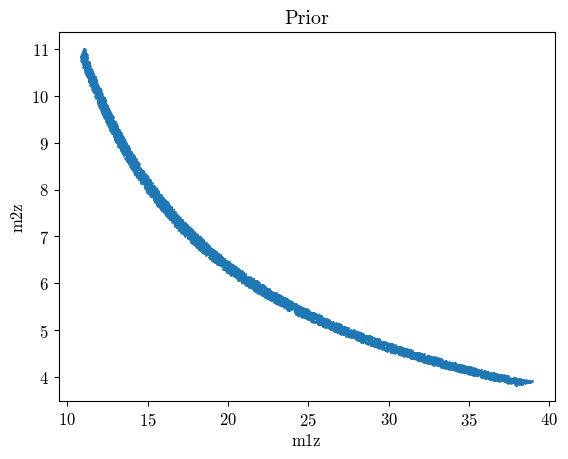

In [11]:
# The detector-frame m1--m2 prior
# As we can see, there are mass cuts

plt.scatter(m1z_pri, m2z_pri, s=1)
plt.xlabel('m1z')
plt.ylabel('m2z')
plt.title('Prior');

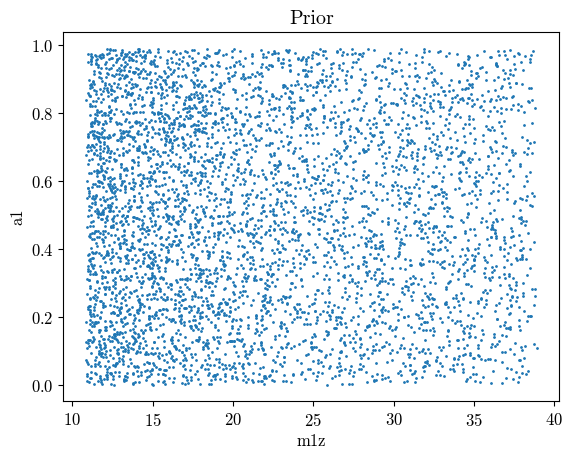

In [12]:
# The detector-frame m1--a1 prior

plt.scatter(m1z_pri, a1_pri, s=1)
plt.xlabel('m1z')
plt.ylabel('a1')
plt.title('Prior');

In [13]:
# We can also estimate the normalized prior with a KDE fit to prior samples
# We will include mass and redshift here, unlike above
# We need to know the maximum redshift for normalization
# But the normalization cancels between population model and PE prior
# So just make sure the max is greater than the largest redshift sample

kde = KDE([m1z_pri, m2z_pri, a1_pri])

def pri_at_pos_kde(x):

    m1, q, a1, z = x
    m1z = m1 * (1 + z)
    m2z = q * m1z

    return (
        kde.pdf([m1z, m2z, a1]) *
        redshift_model(z) *
        pri_at_pos_jacobian(m1, z)
        )

# This will be slow because the prior evluations call the KDE
# We could evaluate the prior KDE just once instead:

kde_evals = pri_at_pos_kde([m1, q, a1, z])
pri_at_pos_kde = lambda x: kde_evals

# The kaydee.KDE pdf and log_pdf methods have a multiprocess option to speed it up
# e.g., kaydee.KDE(samples).pdf(points, processes=8)

# Population Model

### Take each cluster independently

In [14]:
# We assume the rest of the model matches the PE prior
# In particular we assume the redshift model equals the cosmological PE prior
# redshift p(z) ~ dV/dz / (1+z)
# However, we do not know the normalization, i.e., the maximum redshift
# This won't matter for relative Bayes factors

In [15]:
bbhfile = '/home/tristan-bruel/Documents/Science/Great-Balls-of-FIRE/FIRE-2/grid/allBBHs_withKremer.dat'
mbh1, mbh2, abh1, abh2 = np.loadtxt(bbhfile, usecols=[4,5,8,9]).T
abh1[mbh1<mbh2], abh2[mbh1<mbh2] = abh2[mbh1<mbh2], abh1[mbh1<mbh2]
mbh1, mbh2 = np.maximum(mbh1,mbh2), np.minimum(mbh1,mbh2)
qbbh = mbh2 /mbh1 
print('Total number of BBH mergers in CMC clusters: {}'.format(len(mbh1)))
print('Number of hierarchical BBH mergers: {}\n'.format(np.sum(abh1+abh2>0)))
GW24x = (mbh1 < 30) & (qbbh < 0.85) & (abh1 > 0.05)
print('Number of GW24x-like BBH mergers: {}\n'.format(np.sum(GW24x)))

Total number of BBH mergers in CMC clusters: 20899
Number of hierarchical BBH mergers: 3365

Number of GW24x-like BBH mergers: 1412



In [16]:
bh_cl_id = np.loadtxt(bbhfile, usecols=0, skiprows=1, dtype=np.str_)
unique, counts = np.unique(bh_cl_id, return_counts=True)
print('Number of clusters having at least 1 BBH merger:', len(unique))
print('Max number of BBH mergers in a single cluster:', np.max(counts))

Number of clusters having at least 1 BBH merger: 909
Max number of BBH mergers in a single cluster: 1313


We first create two population models corresponding to the two star clusters that form the most merging BBHs

In [17]:
c0 = unique[np.argsort(counts, axis=0)[-1]]
c1 = unique[np.argsort(counts, axis=0)[-2]]

In [18]:
kde0 = KDE([mbh1[bh_cl_id==c0], qbbh[bh_cl_id==c0], abh1[bh_cl_id==c0]])

def model0(x):
    m1, q, a1, z = x
    return kde0.pdf([m1,q,a1]) * redshift_model(z)

In [19]:
#log_bf_nonorm = popodds.log_odds(model0, pri_at_pos_nonorm, [m1, q, a1, z], log=False)
log_bf_nonorm = popodds.log_odds(model0, pri_at_pos_kde, [m1, q, a1, z], log=False)

print('log BF_{cluster0/PE} =', log_bf_nonorm)

log BF_{cluster0/PE} = -4.145951399405743


In [20]:
kde1 = KDE([mbh1[bh_cl_id==c1], qbbh[bh_cl_id==c1], abh1[bh_cl_id==c1]])

def model1(x):
    m1, q, a1, z = x
    return kde1.pdf([m1,q,a1]) * redshift_model(z)

In [21]:
#log_bf_nonorm = popodds.log_odds(model1, pri_at_pos_nonorm, [m1, q, a1, z], log=False)
log_bf_nonorm = popodds.log_odds(model1, pri_at_pos_kde, [m1, q, a1, z], log=False)

print('log BF_{cluster1/PE} =', log_bf_nonorm)

log BF_{cluster1/PE} = -14.443686728508554


In [22]:
log_bfAB_nonorm = popodds.log_odds(
    model0, pri_at_pos_kde, [m1, q, a1, z], log=False, second_model=model1,
    )
print('log BF_{cluster0/cluster1} =', log_bfAB_nonorm)

log BF_{cluster0/cluster1} = 10.29773532910281


Now compute the logBayes factor with respect to the normalised prior for ALL star clusters that produce BBH mergers

In [23]:
tokeep = counts > 5

logB = np.zeros(len(unique[tokeep]))
for n,c in enumerate(unique[tokeep]):
    if np.sum(abh1[bh_cl_id==c]>0)==0:
        logB[n]=np.nan
    else:
        kde_n = KDE([mbh1[bh_cl_id==c], qbbh[bh_cl_id==c], abh1[bh_cl_id==c]])
        
        def modeln(x):
            m1, q, a1, z = x
            return kde_n.pdf([m1,q,a1]) * redshift_model(z)
    
        log_bfAB_nonorm = popodds.log_odds(
            modeln, pri_at_pos_kde, [m1, q, a1, z], log=False,
        )
        print('log BF_{%s/PE} = %f' %(c,log_bfAB_nonorm))
        logB[n] = log_bfAB_nonorm


log BF_{Kremer_1/PE} = -11.161714
log BF_{Kremer_10/PE} = -4.031132
log BF_{Kremer_100/PE} = -14.450105
log BF_{Kremer_102/PE} = -47.315648
log BF_{Kremer_103/PE} = -52.226631
log BF_{Kremer_104/PE} = -11.604096
log BF_{Kremer_106/PE} = -4.990215
log BF_{Kremer_107/PE} = -4.177407
log BF_{Kremer_108/PE} = -4.700624
log BF_{Kremer_11/PE} = -3.598892
log BF_{Kremer_112/PE} = -65.732174
log BF_{Kremer_114/PE} = -33.740419
log BF_{Kremer_115/PE} = -48.916097
log BF_{Kremer_116/PE} = -20.800004
log BF_{Kremer_119/PE} = -13.868151
log BF_{Kremer_12/PE} = -3.721822
log BF_{Kremer_120/PE} = -13.117229
log BF_{Kremer_122/PE} = -59.517582
log BF_{Kremer_123/PE} = -18.360147
log BF_{Kremer_124/PE} = -46.594197
log BF_{Kremer_127/PE} = -42.853956
log BF_{Kremer_128/PE} = -11.050704
log BF_{Kremer_13/PE} = -9.736954
log BF_{Kremer_132/PE} = -5.301018
log BF_{Kremer_135/PE} = -30.038637
log BF_{Kremer_136/PE} = -29.069232
log BF_{Kremer_14/PE} = -12.060961
log BF_{Kremer_140/PE} = -30.510526
log BF_

## Plot cluster properties and Bayes-factor

In [24]:
print(np.nanmin(logB),np.nanmax(logB))

-238.11495185027064 -2.3493665754452646


In [ ]:
cluster_file = '/home/tristan-bruel/Documents/Science/Great-Balls-of-FIRE/FIRE-2/grid/gridClusters_withKremer.hdf5'
with h5py.File(cluster_file) as c:
        cluster_masses = c['Mass'][()]
        cluster_radii = c['HalfMassRadius'][()]
        cluster_metallicities = c['Metallicity'][()]
        cluster_ids = c['id'][()]
        cluster_nBBHs = c['nBBHs'][()]
cluster_ids = np.astype(cluster_ids, np.str_)
print('Number of clusters in the grid:', len(cluster_ids))
print('Number of clusters having at least 1 BBH merger:', np.sum(cluster_nBBHs>0))
print('Max number of BBH mergers in a single cluster:', np.max(cluster_nBBHs),'\n')

#####################################
# Plot your result
fs = 10
lw = 1.4
plt.rc('font', family='serif')
plt.rc('lines', linewidth=lw)
plt.rc('text', usetex=True)

fig, axes = plt.subplots(2, 2, figsize=(12.,9.))
cmap = plt.get_cmap('viridis')

mbins = np.linspace(4,8,41)
rbins = np.linspace(-2,2,41)
Zbins = np.linspace(-2,1,31)
Zsun = 0.017

## First row: number of BBH mergers ##

# First plot: Mcl vs rhm
ax = axes[0,0]
norm = mpl.colors.LogNorm(vmin=1e0, vmax=2e3)
# Clusters with no BBH merger
quiet = cluster_nBBHs==0
ax.scatter(np.log10(cluster_masses[quiet]),
           np.log10(cluster_radii[quiet]),
           c='gray', s=2**2,
           )
# Clusters that produce at least 1 BBH merger
ax.scatter(np.log10(cluster_masses[~quiet]),
           np.log10(cluster_radii[~quiet]),
           c=cmap(norm(cluster_nBBHs[~quiet])), s=3**2,
           )
# Print lines of constant density
densities = np.array([1, 1e3, 1e6, 1e9])
Mplot = np.logspace(4.5,8,1001)
labels = np.array([r'$10^{%i}$' %np.log10(rho) for rho in densities[:-1]])
labels = np.append(labels, r'$\rho_\mathrm{cl}= 10^9\ \mathrm{M}_\odot \mathrm{pc}^{-3}$')
xtext = np.array([5.8, 6.7, 6.7, 5.3])
ytext = np.log10((np.power(10,xtext) /(4/3 *np.pi *densities))**(1/3)) +0.05
ytext[-1] += 0.05
for k,rho in enumerate(densities):
    rplot = (Mplot /(4/3 *np.pi *rho))**(1/3)
    ax.plot(np.log10(Mplot), np.log10(rplot),
            c='dimgray', linestyle='--', zorder=0,
            )
    ax.text(xtext[k], ytext[k], labels[k],
            c='dimgray', fontsize=fs,
            rotation=12, rotation_mode='anchor',
            )
### Show clusters that host GW241011-like BBH mergers ###
uni, indexes = np.unique(bh_cl_id[GW24x], return_index=True)
lochost = np.array([np.where(cluster_ids==u)[0][0] for u in uni])
print('Looking for BBH mergers with stricly positive primary spin, m1 < 30 Msun, and unequal masses (q<0.85)')
print('Number of events found:', np.sum(GW24x))
print('Number of clusters hosting these events:', len(lochost))
print('Total number of BBH mergers from these clusters:',np.sum(cluster_nBBHs[lochost]),'\n')
ax.scatter(np.log10(cluster_masses[lochost]),
           np.log10(cluster_radii[lochost]),
           edgecolor='r', facecolor=cmap(norm(cluster_nBBHs[lochost])),
           linewidth=.6, s=5**2,
           )
ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(r_\mathrm{hm}/\mathrm{pc})$', fontsize=fs)
#ax.set_ylim(ymin=-1.7, ymax=2.3)
ax.set_yticks(np.linspace(-1,2,4))
ax.set_box_aspect(1)

# Second plot: Mcl vs Z #
ax=axes[0,1]
# Clusters with no BBH merger
ax.scatter(np.log10(cluster_masses[quiet]),
           np.log10(cluster_metallicities[quiet] /Zsun),
           c='gray', s=2**2,
           )
# Clusters that produce at least 1 BBH merger
ax.scatter(np.log10(cluster_masses[~quiet]),
           np.log10(cluster_metallicities[~quiet] /Zsun),
           c=cmap(norm(cluster_nBBHs[~quiet])), s=3**2,
           )
ax.scatter(np.log10(cluster_masses[lochost]),
           np.log10(cluster_metallicities[lochost]/Zsun),
           edgecolor='r', facecolor=cmap(norm(cluster_nBBHs[lochost])),
           linewidth=.6, s=5**2,
           )
ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(Z_\mathrm{cl}/\mathrm{Z}_\odot)$', fontsize=fs)
ax.set_ylim(ymin=-2, ymax=1)
ax.set_yticks(np.linspace(-2.,1.,7))
ax.set_box_aspect(1)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axes[0,:], fraction=0.086, pad=0.06, aspect=10)
#cbar.set_label(r'$\mathrm{d}^2\mathrm{N}_\mathrm{cl}/\mathrm{d}M_\mathrm{cl}\mathrm{d}X_\mathrm{cl}$', fontsize=fs)
cbar.set_label(r'Number of BBH mergers', fontsize=fs)
cbar.ax.tick_params(labelsize=0.8*fs)


## Second row: logB ##
clids = unique[tokeep][~np.isnan(logB)]
logBplot = logB[~np.isnan(logB)]
pos_toplogB = np.argsort(logBplot)[-101:]
clids_toplogB = clids[pos_toplogB]
toplogB = logBplot[pos_toplogB]
# logBpos = logBplot[logBplot > 0]
# clids_logBpos = clids[logBplot > 0]

norm = mpl.colors.Normalize(vmin=-50, vmax=5)
#norm = mpl.colors.LogNorm(vmin=9e0, vmax=2e2)
# First plot: Mcl vs rhm
ax = axes[1,0]
loc = np.array([np.where(cluster_ids==u)[0][0] for u in clids])
ax.scatter(np.log10(cluster_masses[loc]),
           np.log10(cluster_radii[loc]),
           c=cmap(norm(logBplot)), s=3**2,
           )
# locmax = np.array([np.where(cluster_ids==u)[0][0] for u in clids_maxB])
# ax.scatter(np.log10(cluster_masses[locmax]),
#            np.log10(cluster_radii[locmax]),
#            edgecolor='r',linewidth=.6, s=5**2,facecolor=cmap(norm(logBplot[getmax]))
#            )
locpos = np.array([np.where(cluster_ids==u)[0][0] for u in clids_toplogB])
ax.scatter(np.log10(cluster_masses[locpos]),
           np.log10(cluster_radii[locpos]),
           edgecolor='r',linewidth=.6, s=5**2,facecolor=cmap(norm(toplogB))
           )

# Print lines of constant density
densities = np.array([1, 1e3, 1e6, 1e9])
Mplot = np.logspace(4.5,8,1001)
labels = np.array([r'$10^{%i}$' %np.log10(rho) for rho in densities[:-1]])
labels = np.append(labels, r'$\rho_\mathrm{cl}= 10^9\ \mathrm{M}_\odot \mathrm{pc}^{-3}$')
xtext = np.array([5.8, 6.7, 6.7, 5.3])
ytext = np.log10((np.power(10,xtext) /(4/3 *np.pi *densities))**(1/3)) +0.05
ytext[-1] += 0.05
for k,rho in enumerate(densities):
    rplot = (Mplot /(4/3 *np.pi *rho))**(1/3)
    ax.plot(np.log10(Mplot), np.log10(rplot),
            c='dimgray', linestyle='--', zorder=0,
            )
    ax.text(xtext[k], ytext[k], labels[k],
            c='dimgray', fontsize=fs,
            rotation=12, rotation_mode='anchor',
            )

ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(r_\mathrm{hm}/\mathrm{pc})$', fontsize=fs)
#ax.set_ylim(ymin=-1.7, ymax=2.3)
ax.set_yticks(np.linspace(-1,2,4))
ax.set_box_aspect(1)

# Second plot: Mcl vs Z #
ax = axes[1,1]
ax.scatter(np.log10(cluster_masses[loc]),
           np.log10(cluster_metallicities[loc]/Zsun),
           c=cmap(norm(logBplot)), s=3**2,
           )
# ax.scatter(np.log10(cluster_masses[locmax]),
#            np.log10(cluster_metallicities[locmax]/Zsun),
#            edgecolor='r',linewidth=.6, s=5**2,facecolor=cmap(norm(logBplot[getmax]))
#            )
ax.scatter(np.log10(cluster_masses[locpos]),
           np.log10(cluster_metallicities[locpos]/Zsun),
           edgecolor='r',linewidth=.6, s=5**2,facecolor=cmap(norm(toplogB))
           )
ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(Z_\mathrm{cl}/\mathrm{Z}_\odot)$', fontsize=fs)
ax.set_ylim(ymin=-2, ymax=1)
ax.set_yticks(np.linspace(-2.,1.,7))
ax.set_box_aspect(1)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axes[1,:], fraction=0.086, pad=0.06, aspect=10)
#cbar.set_label(r'$\mathrm{d}^2\mathrm{N}_\mathrm{cl}/\mathrm{d}M_\mathrm{cl}\mathrm{d}X_\mathrm{cl}$', fontsize=fs)
cbar.set_label(r'$\mathrm{ln}\ \mathcal{B}$', fontsize=fs)
cbar.ax.tick_params(labelsize=0.8*fs)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.,5.))

# First plot: Mcl vs rhm
ax=axes[0]
ax.scatter(np.log10(cluster_masses[lochost]),
           np.log10(cluster_radii[lochost]),
           marker='x',color='r',label='host'
           )
# ax.scatter(np.log10(cluster_masses[locmax]),
#            np.log10(cluster_radii[locmax]),
#            marker='^',color='orange',label=r'$\mathrm{ln}\ \mathcal{B}$'
#            )
ax.scatter(np.log10(cluster_masses[locpos]),
           np.log10(cluster_radii[locpos]),
           marker='^',color='orange',label=r'$101\ \mathrm{highest}\ \mathrm{ln}\ \mathcal{B}$'
           )

ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(r_\mathrm{hm}/\mathrm{pc})$', fontsize=fs)
#ax.set_ylim(ymin=-1.7, ymax=2.3)
ax.set_yticks(np.linspace(-1,2,4))
ax.legend(loc='upper left', fontsize=fs)
ax.set_box_aspect(1)

# Second plot: Mcl vs Z #
ax=axes[1]
ax.scatter(np.log10(cluster_masses[lochost]),
           np.log10(cluster_metallicities[lochost]/Zsun),
           marker='x',color='r'
           )
# ax.scatter(np.log10(cluster_masses[locmax]),
#            np.log10(cluster_metallicities[locmax]/Zsun),
#            marker='^',color='orange'
#            )
ax.scatter(np.log10(cluster_masses[locpos]),
           np.log10(cluster_metallicities[locpos]/Zsun),
           marker='^',color='orange'
           )

ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(Z_\mathrm{cl}/\mathrm{Z}_\odot)$', fontsize=fs)
ax.set_ylim(ymin=-2, ymax=1)
ax.set_yticks(np.linspace(-2.,1.,7))
ax.set_box_aspect(1)

### Group clusters around their metallicity

We now create three population models corresponding to the star clusters simulated around different metallicity values

In [ ]:
Z = np.loadtxt(bbhfile, usecols=[1])

Zero-ish metallicity 

In [ ]:
tokeep = np.abs(np.log10(Z/(0.01*Zsun))) < 0.25

kde0 = KDE([mbh1[tokeep], qbbh[tokeep], abh1[tokeep]])

def model_001Zsun(x):
    m1, q, a1, z = x
    return kde0.pdf([m1,q,a1]) * redshift_model(z)

log_bf_nonorm = popodds.log_odds(model_001Zsun, pri_at_pos_kde, [m1, q, a1, z], log=False)
print('log BF_{0-ish metallicity clusters/PE} =', log_bf_nonorm)

Sub-solar metallicity 

In [ ]:
tokeep = np.abs(np.log10(Z/(0.1*Zsun))) < 0.25

kde0 = KDE([mbh1[tokeep], qbbh[tokeep], abh1[tokeep]])

def model_01Zsun(x):
    m1, q, a1, z = x
    return kde0.pdf([m1,q,a1]) * redshift_model(z)

log_bf_nonorm = popodds.log_odds(model_01Zsun, pri_at_pos_kde, [m1, q, a1, z], log=False)
print('log BF_{sub-solar metallicity clusters/PE} =', log_bf_nonorm)

Solar metallicity 

In [ ]:
tokeep = np.abs(np.log10(Z/Zsun)) < 0.25

kde0 = KDE([mbh1[tokeep], qbbh[tokeep], abh1[tokeep]])

def model_Zsun(x):
    m1, q, a1, z = x
    return kde0.pdf([m1,q,a1]) * redshift_model(z)

log_bf_nonorm = popodds.log_odds(model_Zsun, pri_at_pos_kde, [m1, q, a1, z], log=False)
print('log BF_{solar metallicity clusters/PE} =', log_bf_nonorm)

# With selection effects

### Injection file for GWTC-3

In [ ]:
# # We compute population detection fractions by reweighting recovered injections
# # First let's grab the recovered p(det|theta)=1 injections using FAR<1

# cut_far = 1

# ### Problem here: these injections correspond to GWTC-3, while the events of interest are from O4a ###
# file = './data/endo3_bbhpop-LIGO-T2100113-v12.hdf5'
# with h5py.File(file, 'r') as h:
#     d = h['injections']
    
#     ifars = np.max([d[par][:] for par in d if 'ifar' in par], axis=0)
#     found = ifars > 1 / cut_far
    
#     m1_found = d['mass1_source'][:][found]
#     m2_found = d['mass2_source'][:][found]
#     spin1x_found = d['spin1x'][:][found]
#     spin1y_found = d['spin1y'][:][found]
#     spin1z_found = d['spin1z'][:][found]
#     z_found = d['redshift'][:][found]
        
#     prior_m_found = d['mass1_source_mass2_source_sampling_pdf'][:][found]
#     prior_a1_found = d['spin1x_spin1y_spin1z_sampling_pdf'][:][found]
#     prior_z_found = d['redshift_sampling_pdf'][:][found]

In [ ]:
# # See https://zenodo.org/record/5546676 for the injection distribution

# # joint source-frame primary mass and mass ratio

# def powerlaw(x, lo, hi, slope):
    
#     shape = x**slope
#     norm = (slope + 1) / (hi**(slope + 1) - lo**(slope + 1))
#     cut = (lo < x) * (x < hi)
    
#     return shape * norm * cut

# pow_mass1 = -2.35
# min_mass1 = 2
# max_mass1 = 100
# min_mass2 = 2
# pow_mass2 = 1

# def prior_inj_m(m1, m2):
    
#     return (
#         powerlaw(m1, min_mass1, max_mass1, pow_mass1) *
#         powerlaw(m2, min_mass2, m1, pow_mass2)
#         )

# # redshift p(z) ~ dV/dz * (1+z)^(z_pow-1)

# z_max = 1.9
# z_pow = 1

# prior_inj_z = PowerlawRedshift(z_max=z_max, z_pow=z_pow).prob

# # spin uniform in magnitude between zero and a maximum spin (max_spin)
# max_spin1=0.998
# def prior_inj_a1(spinx,spiny,spinz):

#     cut = np.sqrt(spinx**2+spiny**2+spinz**2)<=max_spin1**2
#     shape = 1/(4*np.pi*(spinx**2 + spiny**2 + spinz**2) * max_spin1)
    
#     return  cut*shape

In [ ]:
# # Check the injection distributions

# plt.hist(
#     (prior_inj_m(m1_found, m2_found) - prior_m_found) / prior_m_found,
#     bins=100,
#     )
# plt.show()

# plt.hist(
#     (prior_inj_z(z_found) - prior_z_found) / prior_z_found,
#     bins=100,
#     )
# plt.show()

# a1_found = np.sqrt(spin1x_found**2+spin1y_found**2+spin1z_found**2)
# plt.hist(
#     (prior_inj_a1(spin1x_found,spin1y_found,spin1z_found) - prior_a1_found) / prior_a1_found,
#     bins=100,
#     )
# plt.show()

# # Not quite the same... Should be fine


### LOAD INJECTIONS FROM O4a 

In [ ]:
filename_injections = "/home/tristan-bruel/Documents/Science/LVK/o4a-astro/injections/samples-rpo4a_v2_20250503133839UTC-1366933504-23846400.hdf"
with h5py.File(filename_injections, 'r') as obj:
    far = np.min([obj['events']['%s_far'%search][:] for search in obj.attrs['searches']], axis=0)
    found = far < cut_far
    weights = obj['events']['weights'][:]

    m1_found = obj['events']['mass1_source'][:][found]
    m2_found = obj['events']['mass2_source'][:][found]
    z_found = obj['events']['z'][:][found]
    spin1x_found = obj['events']['spin1x'][:][found]
    spin1y_found = obj['events']['spin1y'][:][found]
    spin1z_found = obj['events']['spin1z'][:][found]
        
    lnprob_m1_found = obj['events']['lnpdraw_mass1_source'][:][found]
    lnprob_m2_given_m1_found = obj['events']['lnpdraw_mass2_source_GIVEN_mass1_source'][:][found]
    lnprob_a1_found = obj['events']['lnpdraw_spin1_magnitude'][:][found]
    lnprob_z_found = obj['events']['lnpdraw_z'][:][found]

In [ ]:
# See https://zenodo.org/record/5546676 for the injection distribution

# joint source-frame primary mass and mass ratio

def pm1(x):
    if x<1:
        shape = 0
    elif (x>=1) and (x<3):
        shape = 1.0
    elif (x>=3) and (x<8):
        shape = (x/3)**(-4)
    elif (x>=8) and (x<50):
        shape = (8/3)**(-4)*(x/8)**(-1)
    elif (x>=50) and (x<200):
        shape = (8/3)**(-4)*(50/8)**(-1)*(x/50)**(-4)
    elif (x>=200) and (x<1000):
        shape = (8/3)**(-4)*(50/8)**(-1)*(200/50)**(-4)*(x/200)**(-1)
    else:
        shape = 0

    norm = (3-1) \
        + (1/3)**(-4)*(1/(-3/(8**(-3)-3**(-3)))) \
        + (8/3)**(-4)*(1/8)**(-1)*(np.log(50/8)) \
        + (8/3)**(-4)*(50/8)**(-1)*(1/50)**(-4)*(1/(-3/(200**(-3)-50**(-3)))) \
        + (8/3)**(-4)*(50/8)**(-1)*(200/50)**(-4)*(1/200)**(-1)*(np.log(1000/200))

    return shape /norm
    
pm1 = np.vectorize(pm1)

def pm2(x,m1):
    shape = 2*x /(m1**2 - 1)
    cut = (x >= 1) * (x <= m1)
    return shape*cut


def prior_inj_m(m1, m2):
    return pm1(m1)*pm2(m2,m1)


# redshift p(z) ~ dV/dz * (1+z)^(z_pow-1)

z_max = 3.
z_pow = 1

prior_inj_z = PowerlawRedshift(z_max=z_max, z_pow=z_pow).prob

# Component spins are i.i.d. with a truncated Gaussian for the spin magnitude (s) centered at zero with a standard deviation of 0.5
def prior_inj_s(x):
    shape = np.exp(-2*x**2)
    norm = np.sqrt(np.pi) /(2*np.sqrt(2)) *erf(np.sqrt(2))
    return  shape /norm

In [ ]:
# Check the injection distributions
plt.hist(
    (pm1(m1_found) - np.exp(lnprob_m1_found)) / np.exp(lnprob_m1_found),
    bins=100,
    )
plt.show()

In [ ]:
# Check the injection distributions

lnprob_m_found = lnprob_m1_found + lnprob_m2_given_m1_found
plt.hist(
    (prior_inj_m(m1_found, m2_found) - np.exp(lnprob_m_found)) / np.exp(lnprob_m_found),
    bins=100,
    )
plt.show()

plt.hist(
    (prior_inj_z(z_found) - np.exp(lnprob_z_found)) / np.exp(lnprob_z_found),
    bins=np.linspace(-0.01,0.01,100),
    )
plt.show()

a1_found = np.sqrt(spin1x_found**2+spin1y_found**2+spin1z_found**2)
plt.hist(
    (prior_inj_s(a1_found) - np.exp(lnprob_a1_found)) / np.exp(lnprob_a1_found),
    bins=100,
    )
plt.show()

### Detection-conditioned Bayes factors between two models

In [ ]:
# To include selection effects we define a dictionary as follows

q_found = m2_found / m1_found

def prior_inj(x):
    
    m1, q, a1, z = x
    m2 = q * m1
    jacobian = m1
    
    # return jacobian * prior_inj_m(m1, m2) * prior_inj_z(z) * prior_inj_a1(a1,np.zeros_like(a1),np.zeros_like(a1))
    return jacobian * prior_inj_m(m1, m2) * prior_inj_z(z) * prior_inj_s(a1)

detectable = dict(
    samples=[m1_found, q_found, a1_found, z_found],
    prior=prior_inj
    )

# Now compute the detection-conditioned Bayes factor between A and B

log_bfABdet_kde = popodds.log_odds(
    model0, pri_at_pos_kde, [m1, q, a1, z], log=False, second_model=model1,
    detectable=detectable,
    )
print('log BF_{cluster0/cluster1}_det =', log_bfABdet_kde)

log_bfAB_nonorm = popodds.log_odds(
    model0, pri_at_pos_kde, [m1, q, a1, z], log=False, second_model=model1,
    )
print('log BF_{cluster0/cluster1} =', log_bfAB_nonorm)

In [ ]:
tokeep = counts > 10

logD = np.zeros(len(unique[tokeep]))
for n,c in enumerate(unique[tokeep]):
    if np.sum(abh1[bh_cl_id==c]>0)==0:
        logD[n]=np.nan
    else:
        kde_n = KDE([mbh1[bh_cl_id==c], qbbh[bh_cl_id==c], abh1[bh_cl_id==c]])
        
        def modeln(x):
            m1, q, a1, z = x
            return kde_n.pdf([m1,q,a1]) * redshift_model(z)
    
        log_bfAB_nonorm = popodds.log_odds(
            modeln, pri_at_pos_kde, [m1, q, a1, z], log=False, second_model=model0,
            #modeln, pri_at_pos_nonorm, [m1, q, a1, z], log=False,
            detectable=detectable,
        )
        print('log BF_{%s/cluster0}_det = %f' %(c,log_bfAB_nonorm))
        logD[n] = log_bfAB_nonorm


In [ ]:
print(np.nanmin(logD),np.nanmax(logD))

In [ ]:
#####################################
# Plot your result
fs = 10
lw = 1.4
plt.rc('font', family='serif')
plt.rc('lines', linewidth=lw)
plt.rc('text', usetex=True)

fig, axes = plt.subplots(3, 2, figsize=(12.,12.))
cmap = plt.get_cmap('viridis')

mbins = np.linspace(4,8,41)
rbins = np.linspace(-2,2,41)
Zbins = np.linspace(-2,1,31)
Zsun = 0.017

## First row: number of BBH mergers ##

# First plot: Mcl vs rhm
ax = axes[0,0]
norm = mpl.colors.LogNorm(vmin=1e0, vmax=2e3)
# Clusters with no BBH merger
quiet = cluster_nBBHs==0
ax.scatter(np.log10(cluster_masses[quiet]),
           np.log10(cluster_radii[quiet]),
           c='gray', s=2**2,
           )
# Clusters that produce at least 1 BBH merger
ax.scatter(np.log10(cluster_masses[~quiet]),
           np.log10(cluster_radii[~quiet]),
           c=cmap(norm(cluster_nBBHs[~quiet])), s=3**2,
           )
# Print lines of constant density
densities = np.array([1, 1e3, 1e6, 1e9])
Mplot = np.logspace(4.5,8,1001)
labels = np.array([r'$10^{%i}$' %np.log10(rho) for rho in densities[:-1]])
labels = np.append(labels, r'$\rho_\mathrm{cl}= 10^9\ \mathrm{M}_\odot \mathrm{pc}^{-3}$')
xtext = np.array([5.8, 6.7, 6.7, 5.3])
ytext = np.log10((np.power(10,xtext) /(4/3 *np.pi *densities))**(1/3)) +0.05
ytext[-1] += 0.05
for k,rho in enumerate(densities):
    rplot = (Mplot /(4/3 *np.pi *rho))**(1/3)
    ax.plot(np.log10(Mplot), np.log10(rplot),
            c='dimgray', linestyle='--', zorder=0,
            )
    ax.text(xtext[k], ytext[k], labels[k],
            c='dimgray', fontsize=fs,
            rotation=12, rotation_mode='anchor',
            )
### Show clusters that host GW241011-like BBH mergers ###
uni, indexes = np.unique(bh_cl_id[GW24x], return_index=True)
lochost = np.array([np.where(cluster_ids==u)[0][0] for u in uni])
print('Looking for BBH mergers with stricly positive primary spin, m1 < 30 Msun, and unequal masses (q<0.85)')
print('Number of events found:', np.sum(GW24x))
print('Number of clusters hosting these events:', len(lochost))
print('Total number of BBH mergers from these clusters:',np.sum(cluster_nBBHs[lochost]),'\n')
ax.scatter(np.log10(cluster_masses[lochost]),
           np.log10(cluster_radii[lochost]),
           edgecolor='r', facecolor=cmap(norm(cluster_nBBHs[lochost])),
           linewidth=.6, s=5**2,
           )
ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(r_\mathrm{hm}/\mathrm{pc})$', fontsize=fs)
#ax.set_ylim(ymin=-1.7, ymax=2.3)
ax.set_yticks(np.linspace(-1,2,4))
ax.set_box_aspect(1)

# Second plot: Mcl vs Z #
ax=axes[0,1]
# Clusters with no BBH merger
ax.scatter(np.log10(cluster_masses[quiet]),
           np.log10(cluster_metallicities[quiet] /Zsun),
           c='gray', s=2**2,
           )
# Clusters that produce at least 1 BBH merger
ax.scatter(np.log10(cluster_masses[~quiet]),
           np.log10(cluster_metallicities[~quiet] /Zsun),
           c=cmap(norm(cluster_nBBHs[~quiet])), s=3**2,
           )
ax.scatter(np.log10(cluster_masses[lochost]),
           np.log10(cluster_metallicities[lochost]/Zsun),
           edgecolor='r', facecolor=cmap(norm(cluster_nBBHs[lochost])),
           linewidth=.6, s=5**2,
           )
ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(Z_\mathrm{cl}/\mathrm{Z}_\odot)$', fontsize=fs)
ax.set_ylim(ymin=-2, ymax=1)
ax.set_yticks(np.linspace(-2.,1.,7))
ax.set_box_aspect(1)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axes[0,:], fraction=0.086, pad=0.06, aspect=10)
#cbar.set_label(r'$\mathrm{d}^2\mathrm{N}_\mathrm{cl}/\mathrm{d}M_\mathrm{cl}\mathrm{d}X_\mathrm{cl}$', fontsize=fs)
cbar.set_label(r'Number of BBH mergers', fontsize=fs)
cbar.ax.tick_params(labelsize=0.8*fs)


## Second row: logB ##
clids = unique[tokeep][~np.isnan(logB)]
logBplot = logB[~np.isnan(logB)]
getmax = np.argsort(logBplot)[-11:]
clids_maxB = clids[getmax]

#norm = mpl.colors.Normalize(vmin=logBplot.min(), vmax=logBplot.max())
norm = mpl.colors.Normalize(vmin=-100, vmax=0)
#norm = mpl.colors.LogNorm(vmin=9e0, vmax=2e2)
# First plot: Mcl vs rhm
ax = axes[1,0]
loc = np.array([np.where(cluster_ids==u)[0][0] for u in clids])
ax.scatter(np.log10(cluster_masses[loc]),
           np.log10(cluster_radii[loc]),
           c=cmap(norm(logBplot)), s=3**2,
           )
locmax = np.array([np.where(cluster_ids==u)[0][0] for u in clids_maxB])
ax.scatter(np.log10(cluster_masses[locmax]),
           np.log10(cluster_radii[locmax]),
           edgecolor='r',linewidth=.6, s=5**2,facecolor=cmap(norm(logBplot[getmax]))
           )

# Print lines of constant density
densities = np.array([1, 1e3, 1e6, 1e9])
Mplot = np.logspace(4.5,8,1001)
labels = np.array([r'$10^{%i}$' %np.log10(rho) for rho in densities[:-1]])
labels = np.append(labels, r'$\rho_\mathrm{cl}= 10^9\ \mathrm{M}_\odot \mathrm{pc}^{-3}$')
xtext = np.array([5.8, 6.7, 6.7, 5.3])
ytext = np.log10((np.power(10,xtext) /(4/3 *np.pi *densities))**(1/3)) +0.05
ytext[-1] += 0.05
for k,rho in enumerate(densities):
    rplot = (Mplot /(4/3 *np.pi *rho))**(1/3)
    ax.plot(np.log10(Mplot), np.log10(rplot),
            c='dimgray', linestyle='--', zorder=0,
            )
    ax.text(xtext[k], ytext[k], labels[k],
            c='dimgray', fontsize=fs,
            rotation=12, rotation_mode='anchor',
            )

ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(r_\mathrm{hm}/\mathrm{pc})$', fontsize=fs)
#ax.set_ylim(ymin=-1.7, ymax=2.3)
ax.set_yticks(np.linspace(-1,2,4))
ax.set_box_aspect(1)

# Second plot: Mcl vs Z #
ax = axes[1,1]
ax.scatter(np.log10(cluster_masses[loc]),
           np.log10(cluster_metallicities[loc]/Zsun),
           c=cmap(norm(logBplot)), s=3**2,
           )
ax.scatter(np.log10(cluster_masses[locmax]),
           np.log10(cluster_metallicities[locmax]/Zsun),
           edgecolor='r',linewidth=.6, s=5**2,facecolor=cmap(norm(logBplot[getmax]))
           )
ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(Z_\mathrm{cl}/\mathrm{Z}_\odot)$', fontsize=fs)
ax.set_ylim(ymin=-2, ymax=1)
ax.set_yticks(np.linspace(-2.,1.,7))
ax.set_box_aspect(1)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axes[1,:], fraction=0.086, pad=0.06, aspect=10)
#cbar.set_label(r'$\mathrm{d}^2\mathrm{N}_\mathrm{cl}/\mathrm{d}M_\mathrm{cl}\mathrm{d}X_\mathrm{cl}$', fontsize=fs)
cbar.set_label(r'$\mathrm{ln}\ \mathcal{B}$', fontsize=fs)
cbar.ax.tick_params(labelsize=0.8*fs)


## Third row: logD ##
clids = unique[tokeep][~np.isnan(logD)]
logDplot = logD[~np.isnan(logD)]
getmax=np.argsort(logDplot)[-11:]
clids_maxD = clids[getmax]

#norm = mpl.colors.Normalize(vmin=logDplot.min(), vmax=logDplot.max())
norm = mpl.colors.Normalize(vmin=-200, vmax=5)
#norm = mpl.colors.LogNorm(vmin=9e0, vmax=2.5e2)
# First plot: Mcl vs rhm
ax = axes[2,0]
loc = np.array([np.where(cluster_ids==u)[0][0] for u in clids])
ax.scatter(np.log10(cluster_masses[loc]),
           np.log10(cluster_radii[loc]),
           c=cmap(norm(logDplot)), s=3**2,
           )
locmax = np.array([np.where(cluster_ids==u)[0][0] for u in clids_maxD])
ax.scatter(np.log10(cluster_masses[locmax]),
           np.log10(cluster_radii[locmax]),
           edgecolor='r',linewidth=.6, s=5**2,facecolor=cmap(norm(logDplot[getmax]))
           )

# Print lines of constant density
densities = np.array([1, 1e3, 1e6, 1e9])
Mplot = np.logspace(4.5,8,1001)
labels = np.array([r'$10^{%i}$' %np.log10(rho) for rho in densities[:-1]])
labels = np.append(labels, r'$\rho_\mathrm{cl}= 10^9\ \mathrm{M}_\odot \mathrm{pc}^{-3}$')
xtext = np.array([5.8, 6.7, 6.7, 5.3])
ytext = np.log10((np.power(10,xtext) /(4/3 *np.pi *densities))**(1/3)) +0.05
ytext[-1] += 0.05
for k,rho in enumerate(densities):
    rplot = (Mplot /(4/3 *np.pi *rho))**(1/3)
    ax.plot(np.log10(Mplot), np.log10(rplot),
            c='dimgray', linestyle='--', zorder=0,
            )
    ax.text(xtext[k], ytext[k], labels[k],
            c='dimgray', fontsize=fs,
            rotation=12, rotation_mode='anchor',
            )

ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(r_\mathrm{hm}/\mathrm{pc})$', fontsize=fs)
#ax.set_ylim(ymin=-1.7, ymax=2.3)
ax.set_yticks(np.linspace(-1,2,4))
ax.set_box_aspect(1)

# Second plot: Mcl vs Z #
ax = axes[2,1]
ax.scatter(np.log10(cluster_masses[loc]),
           np.log10(cluster_metallicities[loc]/Zsun),
           c=cmap(norm(logDplot)), s=3**2,
           )
ax.scatter(np.log10(cluster_masses[locmax]),
           np.log10(cluster_metallicities[locmax]/Zsun),
           edgecolor='r',linewidth=.6, s=5**2,facecolor=cmap(norm(logDplot[getmax]))
           )
ax.set_xlabel(r'$\mathrm{log}(M_\mathrm{cl}/\mathrm{M}_\odot)$', fontsize=fs)
ax.set_xlim(xmin=4.5, xmax=7.1)
ax.set_xticks(np.linspace(5.,7.,5))
ax.set_ylabel(r'$\mathrm{log}(Z_\mathrm{cl}/\mathrm{Z}_\odot)$', fontsize=fs)
ax.set_ylim(ymin=-2, ymax=1)
ax.set_yticks(np.linspace(-2.,1.,7))
ax.set_box_aspect(1)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axes[2,:], fraction=0.086, pad=0.06, aspect=10)
#cbar.set_label(r'$\mathrm{d}^2\mathrm{N}_\mathrm{cl}/\mathrm{d}M_\mathrm{cl}\mathrm{d}X_\mathrm{cl}$', fontsize=fs)
cbar.set_label(r'$\mathrm{ln}\ \mathcal{D}$', fontsize=fs)
cbar.ax.tick_params(labelsize=0.8*fs)

In [ ]:
cluster_logD_max = clids_maxD[-1]
cluster_logD_max

In [ ]:
np.sort(logDplot)[-1]

In [ ]:
mbh1[bh_cl_id==cluster_logD_max]

In [ ]:
qbbh[bh_cl_id==cluster_logD_max]

In [ ]:
abh1[bh_cl_id==cluster_logD_max]